# 04 — Backtest & Stress-Period Scorecard

**Tail Risk Adequacy — Stress-Testing Risk Metrics Across Distributional Assumptions and Market Regimes**
High_Magus_of_Risk

---

## Purpose

Take the Phase 1 forecasts produced by notebook 03 and run the **formal backtest battery** required by the project's evaluation strategy. The battery covers both VaR and ES:

**VaR tests** (asymptotic likelihood-ratio):

1. **Kupiec POF (unconditional coverage)** — is the empirical exception rate consistent with the nominal $1 - \alpha = 1\%$ target? LR statistic $\sim \chi^2(1)$.
2. **Christoffersen independence** — are exceptions independent of each other, or do they cluster? LR statistic $\sim \chi^2(1)$.
3. **Christoffersen conditional coverage (joint)** — both at once. LR $\sim \chi^2(2)$.

**ES tests** (bootstrap-based, on breach days):

4. **McNeil-Frey (2000)** — one-sided bootstrap on exceedance residuals $L_t - \mathrm{ES}_t$. Tests whether ES systematically under-estimates losses on breach days.
5. **Acerbi-Székely (2014) $Z_2$** — single normalised summary statistic with bootstrap CI. Aligned with FRTB-style regulatory evaluation of ES adequacy.

These tests are applied **overall** and on each of the four named stress windows defined in `data/stress_windows.json` (the 2000-03 dot-com bust, GFC, COVID, and 2022 rate hikes). The methodology section below derives each test from first principles before the empirical results are presented.

All test code lives in `src/risk.py` (unit-tested in `tests/test_risk.py`); the notebook-specific wrapper `run_es_backtest` in §5 just imports the formal tests from there and flattens their results into one scorecard row. Notebook 05 (GARCH-FHS) uses the same imported functions.

---
## 1  Environment Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, os.path.abspath('src'))
from risk import (backtest_var_es, kupiec_pof_test, christoffersen_cc_test,
                  mcneil_frey_es_test, acerbi_szekely_z2)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

---
## 2  Configuration

Echoed from notebook 03 so each notebook is independent.

In [2]:
CONFIG = {
    'alpha'      : 0.99,
    'portfolios' : ['Port_FO'],
    'engines'    : ['Gaussian', 't_nu10', 't_nu6', 't_nu4'],
    'portfolio_labels': {
        'Port_FO': 'Family-Office Portfolio (40/25/15/10/10)',
    },
    'engine_colors': {
        'Gaussian': '#1f77b4',
        't_nu10'  : '#f4a261',
        't_nu6'   : '#e76f51',
        't_nu4'   : '#9d0208',
    },
    'window_colors': {
        'DotCom_2000_2003': '#2a9d8f',
        'GFC'             : '#a8324a',
        'COVID'           : '#e09f3e',
        'Rate_Hikes_2022' : '#5e548e',
    },
}
print(f'Confidence: {CONFIG["alpha"]:.0%}   Target exception rate: {1-CONFIG["alpha"]:.1%}')

Confidence: 99%   Target exception rate: 1.0%


---
## 3  Load Returns, Forecasts, and Stress Windows

In [3]:
# Returns
returns = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)

# Forecasts: one frame per portfolio, with 8 columns (engine × {VaR, ES})
forecasts_by_port = {}
for port in CONFIG['portfolios']:
    forecasts_by_port[port] = pd.read_csv(f'data/forecasts/{port}.csv',
                                          index_col=0, parse_dates=True)
    print(f'  {port:<20s} forecasts: {forecasts_by_port[port].shape}, '
          f'range {forecasts_by_port[port].index.min().date()} → '
          f'{forecasts_by_port[port].index.max().date()}')

# Stress windows
with open('data/stress_windows.json') as f:
    STRESS_WINDOWS = json.load(f)
for name, w in STRESS_WINDOWS.items():
    print(f'  Window {name:<18s} {w["start"]} → {w["end"]}')

  Port_FO              forecasts: (6485, 8), range 2000-05-17 → 2026-04-01
  Window DotCom_2000_2003   2000-09-01 → 2003-03-31
  Window GFC                2008-09-15 → 2009-06-30
  Window COVID              2020-02-15 → 2020-05-31
  Window Rate_Hikes_2022    2022-01-01 → 2022-12-31


---
## 4  Methodology — Formal Backtests for VaR and ES

### 4.1  Why we need formal backtests

Notebook 03 reported two kinds of empirical diagnostics per (portfolio × engine):

- For VaR: the empirical exception rate (*"2.30% vs 1% target"*).
- For ES: the average residual on breach days, $\overline{(L_t - \mathrm{ES}_t) \mid I_t = 1}$ (*"+0.495% on Gaussian"*).

Both headlines are intuitive, but they leave three questions open:

1. Is the observed gap statistically significant, or could it plausibly have arisen by chance under a correctly calibrated model?
2. For VaR specifically: are exceptions distributed evenly over time, or do they cluster in volatile regimes?
3. Can we summarise these questions in a small, standard test battery?

The standard answers — used in industry by many major banks and explicitly referenced in the Basel FRTB capital-adequacy framework — combine **likelihood-ratio tests for VaR** (Kupiec 1995; Christoffersen 1998) and **bootstrap-based tests for ES** (McNeil-Frey 2000; Acerbi-Székely 2014). All five tests are derived from first principles in the subsections below.

### 4.2  Notation

For a daily return $r_t$ with realised loss $L_t = -r_t$ and a 1-day-ahead forecast $\mathrm{VaR}_t$ at confidence level $\alpha$, define the **exception indicator**

$$
I_t \;=\; \mathbb{1}\{L_t > \mathrm{VaR}_t\} \;\in\; \{0, 1\}.
$$

Over a backtest sample of length $n$, let

$$
x \;=\; \sum_{t=1}^{n} I_t \qquad\text{(total exceptions)},
\qquad
\hat{\pi} \;=\; x/n \qquad\text{(empirical exception rate)},
\qquad
p \;=\; 1 - \alpha \qquad\text{(nominal exception rate)}.
$$

For $\alpha = 99\%$, $p = 0.01$. We also use the **exceedance residual** $\varepsilon_t = L_t - \mathrm{ES}_t$, defined only on days where $I_t = 1$.

### 4.3  Kupiec POF Test — Unconditional Coverage

**Null hypothesis.** Exceptions are independent Bernoulli draws with the nominal probability:

$$
H_0^{\text{uc}}:\quad I_t \stackrel{\text{iid}}{\sim} \mathrm{Bernoulli}(p).
$$

The model is "correctly calibrated on average."

**Derivation.** Under $H_0$ the joint likelihood of the observed indicator series is

$$
L_0(p) \;=\; p^x (1-p)^{n-x}.
$$

Under the alternative $H_1$ (a Bernoulli with the unrestricted MLE $\hat{\pi}$) it is

$$
L_1(\hat{\pi}) \;=\; \hat{\pi}^x (1-\hat{\pi})^{n-x}.
$$

The likelihood-ratio statistic is

$$
\boxed{\;
\mathrm{LR}_{\mathrm{uc}}
\;=\; -2 \ln \frac{L_0(p)}{L_1(\hat{\pi})}
\;=\; -2 \Big[\, x \ln\!\tfrac{p}{\hat{\pi}} + (n-x) \ln\!\tfrac{1-p}{1-\hat{\pi}} \,\Big].
\;}
$$

By Wilks' theorem, under $H_0^{\text{uc}}$:

$$
\mathrm{LR}_{\mathrm{uc}} \;\xrightarrow{d}\; \chi^2_1.
$$

We reject $H_0^{\text{uc}}$ at the 5% level if $\mathrm{LR}_{\mathrm{uc}} > \chi^2_{0.95}(1) = 3.841$ (as seen in the chi-squared table).

**Edge cases** (handled in `src/risk.py`):
- $x = 0$ (no exceptions): $\mathrm{LR}_{\mathrm{uc}} = -2 n \ln(1-p)$.
- $x = n$ (all exceptions): $\mathrm{LR}_{\mathrm{uc}} = -2 n \ln(p)$.

**Justification — why this test, why now.**
- It is the regulatory benchmark and the most widely cited backtest in the VaR literature.
- The interpretation is the one practitioners and supervisors care about: *"are we getting the right number of breaches?"*
- Asymptotic critical values are tractable; no simulation needed.

**Known limitation.** The test depends only on the *count* $x$, not on *when* the exceptions occur. A pattern of 15 exceptions all in 2008 yields the same $\mathrm{LR}_{\mathrm{uc}}$ as 15 exceptions spread uniformly over 30 years. **This is precisely the gap the Christoffersen test fills**, which is used below.

### 4.4  Christoffersen Independence Test

**Null hypothesis.** The exception indicator follows a first-order Markov chain on $\{0, 1\}$ in which the transition probabilities do **not** depend on the previous state — i.e., the chance of an exception today is the same whether or not yesterday was an exception:

$$
H_0^{\text{ind}}:\quad \pi_{01} \;=\; \pi_{11} \;\equiv\; \pi,
$$

where $\pi_{ij} = \Pr(I_t = j \mid I_{t-1} = i)$.

**Derivation.** Let $n_{ij}$ denote the count of observed transitions from state $i$ to state $j$ over the $n-1$ pairs $(I_{t-1}, I_t)$. The unrestricted MLEs of the Markov transition probabilities are

$$
\hat{\pi}_{01} \;=\; \frac{n_{01}}{n_{00}+n_{01}},
\qquad
\hat{\pi}_{11} \;=\; \frac{n_{11}}{n_{10}+n_{11}},
$$

and the restricted (memoryless) estimate is

$$
\hat{\pi} \;=\; \frac{n_{01}+n_{11}}{n_{00}+n_{01}+n_{10}+n_{11}}.
$$

The two likelihoods are

$$
L_0^{\text{ind}}(\hat{\pi}) \;=\; (1-\hat{\pi})^{\,n_{00}+n_{10}}\;\hat{\pi}^{\,n_{01}+n_{11}},
$$

$$
L_1^{\text{ind}}(\hat{\pi}_{01}, \hat{\pi}_{11}) \;=\;
(1-\hat{\pi}_{01})^{n_{00}}\,\hat{\pi}_{01}^{\,n_{01}}\;
(1-\hat{\pi}_{11})^{n_{10}}\,\hat{\pi}_{11}^{\,n_{11}}.
$$

The likelihood-ratio statistic is

$$
\boxed{\;
\mathrm{LR}_{\mathrm{ind}}
\;=\; -2 \ln \frac{L_0^{\text{ind}}}{L_1^{\text{ind}}}
\;\xrightarrow{d}\; \chi^2_1 \text{ under } H_0^{\text{ind}}.
\;}
$$

Reject at 5%: $\mathrm{LR}_{\mathrm{ind}} > 3.841$.

**Justification — why this test is critical for this project.**
- It catches the failure mode that Kupiec misses: *clustered* exceptions. A rolling-window VaR engine that uses a 4-year σ̂ cannot react to a sudden volatility spike fast enough; the result is a run of exceptions concentrated in the high-volatility regime. The Christoffersen test fires precisely on this pattern.
- It maps directly onto one of the three sub-themes in the project mind-map (*volatility clustering*) — and onto the stylised fact our notebook 02 found most strongly: the Ljung-Box test on $r_t^2$ produced LR $\approx 4{,}400$ at lag 5.
- Without this test, a project that asks *"which distributional engine best captures tail risk?"* would not be able to distinguish a distributional failure (Gaussian under-estimates fat tails) from a *dynamic* failure (any rolling engine under-estimates conditional variance during stress). Those are different problems with different solutions.

### 4.5  Christoffersen Conditional Coverage — Joint Test

**Null hypothesis.** Both coverage *and* independence hold simultaneously:

$$
H_0^{\text{cc}} \;=\; H_0^{\text{uc}} \;\cap\; H_0^{\text{ind}}.
$$

That is, exceptions are iid Bernoulli$(p)$ — the textbook "ideal" behaviour of a perfectly calibrated VaR engine.

**Derivation.** Because the likelihoods nest properly, the two LR statistics add:

$$
\boxed{\;
\mathrm{LR}_{\mathrm{cc}} \;=\; \mathrm{LR}_{\mathrm{uc}} + \mathrm{LR}_{\mathrm{ind}}
\;\xrightarrow{d}\; \chi^2_2 \text{ under } H_0^{\text{cc}}.
\;}
$$

Reject at 5%: $\mathrm{LR}_{\mathrm{cc}} > \chi^2_{0.95}(2) = 5.99$.

**Decomposition is informative.** Reporting both component statistics individually plus the joint is more informative than the joint alone:

| Pattern                                   | Interpretation                                                       |
|-------------------------------------------|----------------------------------------------------------------------|
| Reject $\mathrm{LR}_{\mathrm{uc}}$ only   | Wrong coverage but exceptions don't cluster — distributional miss.   |
| Reject $\mathrm{LR}_{\mathrm{ind}}$ only  | Coverage is right on average but exceptions cluster — wrong dynamics. |
| Reject both                               | Distribution **and** dynamics are wrong — the typical Phase 1 finding. |

### 4.6  From VaR to ES — Why a separate test battery is needed

Up to this point the methodology has only tested **VaR**. The Kupiec and Christoffersen tests both operate on the binary exception indicator $I_t$ — they ask whether breaches happen at the right rate and whether they cluster, but they say nothing about the *severity* of breaches. Two engines can have identical exception counts and identical clustering patterns yet differ dramatically in how badly they understate the loss when a breach actually occurs.

This is exactly what **Expected Shortfall** is designed to measure. By definition, ES is the conditional expected loss given a VaR breach:

$$
\mathrm{ES}_t \;=\; \mathbb{E}\!\left[L_t \,\middle|\, L_t > \mathrm{VaR}_t\right].
$$

So a formal ES backtest asks: *on the days where $L_t > \mathrm{VaR}_t$, do the realised losses match the ES forecast on average?* In NB03 we reported the descriptive statistic $\overline{\varepsilon} = \overline{(L_t - \mathrm{ES}_t)\mid I_t = 1}$, which is informative but lacks a p-value: a small positive value could be a coincidence or could be a systematic miscalibration.

The two formal ES tests we add here both turn this descriptive diagnostic into a hypothesis test, from different angles:

- **McNeil-Frey (2000)** — a one-sided bootstrap test on the exceedance residuals $\varepsilon_t$ restricted to breach days. Gives a transparent p-value for "is ES under-estimating tail losses?".
- **Acerbi-Székely (2014) $Z_2$** — a single normalised summary statistic that compares the realised tail losses to the predicted ES across the full sample. Sign-carrying, FRTB-aligned, reported with a bootstrap confidence interval.

The two tests are complementary: McNeil-Frey gives a clean one-sided p-value on breach-day severity; $Z_2$ gives a single number on a natural scale that summarises ES adequacy. The project reports both.

### 4.7  McNeil-Frey (2000) — Bootstrap Test on Exceedance Residuals

**Setup.** Let $\mathcal{E} = \{t : L_t > \mathrm{VaR}_t\}$ be the set of breach days and $n_e = |\mathcal{E}|$. The **exceedance residual** on each breach day is

$$
\varepsilon_t \;=\; L_t - \mathrm{ES}_t, \qquad t \in \mathcal{E}.
$$

By definition of ES, $\mathbb{E}[L_t \mid I_t = 1] = \mathrm{ES}_t$, so under a correctly calibrated ES model, $\mathbb{E}[\varepsilon_t \mid I_t = 1] = 0$.

**Null and alternative.**

$$
H_0:\; \mathbb{E}[\varepsilon_t \mid I_t = 1] = 0
\qquad \text{vs.} \qquad
H_1:\; \mathbb{E}[\varepsilon_t \mid I_t = 1] > 0.
$$

The alternative is **one-sided** because the practically relevant failure mode is ES *under-estimating* tail losses (positive residuals). Over-estimation is conservative and not a calibration concern.

**Test statistic.** The sample mean of the residuals on breach days,

$$
\bar{\varepsilon} \;=\; \frac{1}{n_e}\sum_{t \in \mathcal{E}} \varepsilon_t.
$$

**Why a bootstrap and not a t-test?** Exceedance residuals are heavy-tailed, possibly correlated through volatility regimes, and the sample size $n_e$ is often small (especially in stress windows). The normal-approximation t-test is unreliable under all three conditions. McNeil-Frey's bootstrap procedure is non-parametric and robust to all of them.

**Bootstrap p-value.** To simulate the null distribution of $\bar{\varepsilon}$ under $H_0$:

1. Centre the observed residuals: $\tilde{\varepsilon}_t = \varepsilon_t - \bar{\varepsilon}$. The centred series has sample mean exactly zero, mimicking $H_0$.
2. Draw $B$ bootstrap samples of size $n_e$ with replacement from $\{\tilde{\varepsilon}_t\}$.
3. Compute the bootstrap mean $\bar{\varepsilon}^{(b)}$ for each.
4. One-sided p-value: $\hat{p} \;=\; B^{-1}\sum_b \mathbb{1}\{\bar{\varepsilon}^{(b)} \geq \bar{\varepsilon}\}$.

We use $B = 10{,}000$ throughout. Reject $H_0$ at 5% when $\hat{p} < 0.05$. Alongside the p-value we report a non-parametric **95% bootstrap CI for the raw residual mean** (resampling the un-centred residuals), giving both significance and magnitude.

**A note on standardisation.** The original McNeil-Frey paper uses *standardised* exceedance residuals $(L_t - \mathrm{ES}_t)/\sigma_t$, which requires access to the model's conditional volatility $\sigma_t$. Phase 1 engines compute σ̂ as part of the forecasting process, but Phase 2 GARCH-FHS produces a cleaner conditional $\sigma_t$. We use the **unstandardised** version here for consistency across engines — the test logic and asymptotic interpretation are unchanged, and the residuals remain in interpretable units (% of portfolio value per day).

### 4.8  Acerbi-Székely (2014) — $Z_2$ Statistic

**Definition.** Acerbi and Székely propose three statistics for ES backtesting; $Z_2$ is the most widely used and is the one most directly aligned with how FRTB-style regulators evaluate ES adequacy. In the project's notation:

$$
\boxed{\;
Z_2 \;=\; -\,\frac{1}{T\,(1-\alpha)} \sum_{t=1}^{T} \frac{L_t\, I_t}{\mathrm{ES}_t} \;+\; 1.
\;}
$$

where $T$ is the total number of forecast days, $I_t = \mathbb{1}\{L_t > \mathrm{VaR}_t\}$, and $\alpha$ is the confidence level.

**Intuition.** Each term $L_t / \mathrm{ES}_t$ on a breach day measures the realised loss as a *multiple* of what ES predicted. Under correct calibration:

- The number of breaches is approximately $T(1-\alpha)$ (Kupiec coverage).
- On each breach day, $L_t \approx \mathrm{ES}_t$ in expectation (correct ES severity).
- The sum of $L_t I_t / \mathrm{ES}_t$ over $T$ days is therefore approximately $T(1-\alpha)$.
- Hence $Z_2 \approx -1 + 1 = 0$.

**Sign interpretation.**

| $Z_2$ sign | Interpretation                                                                              |
|------------|---------------------------------------------------------------------------------------------|
| $Z_2 < 0$  | ES **under-estimates** breach losses (realised losses exceed ES) — *the regulatory concern.* |
| $Z_2 = 0$  | ES correctly calibrated on average.                                                          |
| $Z_2 > 0$  | ES over-estimates breach losses (model is conservative).                                     |

The magnitude is on a natural scale. $Z_2 = -0.10$ means realised breach losses exceed ES forecasts by roughly 10% in aggregate.

**Inference.** The original Acerbi-Székely paper derives critical values by simulating the assumed predictive distribution $F_t$ under $H_0$. For this project we instead report $Z_2$ with a **non-parametric bootstrap confidence interval**: resample the contributions $L_t I_t / \mathrm{ES}_t$ with replacement and recompute $Z_2$ many times. If the 95% bootstrap CI for $Z_2$ excludes 0, we treat this as evidence against correct ES calibration. For formal one-sided hypothesis testing we defer to the McNeil-Frey bootstrap in §4.7, which is the cleaner instrument for that purpose.

**Why include both McNeil-Frey and $Z_2$?** They answer slightly different questions:

- McNeil-Frey: *On breach days, is the average residual significantly different from zero?* A clean one-sided hypothesis test on conditional severity.
- $Z_2$: *Across the full sample, is the model's ES forecast consistent with realised tail behaviour?* A single normalised number with FRTB-aligned interpretation.

Reporting both aligns with academic convention (McNeil-Frey) and regulatory practice (FRTB), and provides a check on robustness: when both agree, the verdict is unambiguous; when they disagree, the diagnostic information about *which* aspect of ES is failing is useful.

### 4.9  How the test battery motivates the project's architecture

Every VaR/ES engine has two distinct calibration questions:

1. **Marginal calibration.** Is the assumed distribution (Gaussian, Student-t, …) consistent with the empirical tail thickness? — **Kupiec answers this on the VaR side; McNeil-Frey and $Z_2$ answer this on the ES side.**
2. **Dynamic calibration.** Does the engine adapt to changing volatility regimes? — **Christoffersen independence answers this.**

Question 1 is what we vary across the four Phase 1 engines (Gaussian, $t_{10}$, $t_{6}$, $t_{4}$ on the same rolling mean/variance). Question 2 is what we will vary in Phase 2 by replacing the rolling $\hat{\sigma}_t$ with a GARCH-filtered conditional volatility (FHS). The dual-test framework is therefore not just a backtest — it is the **evaluation infrastructure** for the project's three-way *metric × distribution × dynamics* comparison.

The predicted pattern that follows naturally:

- Phase 1 t-engines reduce $\mathrm{LR}_{\mathrm{uc}}$, McNeil-Frey, and $|Z_2|$ versus Gaussian (better distribution) but leave $\mathrm{LR}_{\mathrm{ind}}$ roughly unchanged (same dynamics).
- Phase 2 GARCH-FHS should reduce $\mathrm{LR}_{\mathrm{ind}}$ sharply (correct dynamics) and may also reduce the ES tests' rejections, regardless of distributional choice.
- A combined GARCH-FHS-with-t-innovations engine should improve every metric simultaneously.

### 4.10  Why these particular tests, not others?

- **Christoffersen vs. Engle-Manganelli Dynamic Quantile (DQ) test (2004).** The DQ test is more powerful but requires choosing a vector of hits-test instruments. For a project of this scope, Christoffersen is the textbook standard and the more transparent choice.
- **McNeil-Frey vs. Du-Escanciano (2017) cumulative-violation ES test.** Du-Escanciano is asymptotically more powerful but relies on a different functional form (integrated coverage rather than residual mean). McNeil-Frey is the most widely cited and has the cleanest pedagogical link to the descriptive diagnostic already reported in NB03.
- **Acerbi-Székely $Z_2$ vs. $Z_1$ and $Z_3$.** $Z_1$ tests conditional on the observed number of exceptions (decoupling severity from coverage); $Z_3$ tests the rank-uniformity of breach-day losses. $Z_2$ is the most commonly reported in the FRTB-related literature because it summarises both coverage and severity in a single number.
- **POF coverage at multiple confidence levels.** Running the same battery at 95% and 97.5% in addition to 99% is reserved as a sensitivity check.

### 4.11  References

- **Kupiec, P.H.** (1995). "Techniques for Verifying the Accuracy of Risk Measurement Models." *Journal of Derivatives*, 3(2), 73–84.
- **Christoffersen, P.F.** (1998). "Evaluating Interval Forecasts." *International Economic Review*, 39(4), 841–862.
- **McNeil, A.J., and Frey, R.** (2000). "Estimation of Tail-Related Risk Measures for Heteroscedastic Financial Time Series: An Extreme Value Approach." *Journal of Empirical Finance*, 7(3–4), 271–300.
- **Acerbi, C., and Székely, B.** (2014). "Back-Testing Expected Shortfall." *Risk*, 27(11), 76–81.
- **Basel Committee on Banking Supervision** (2019). *Minimum Capital Requirements for Market Risk* (FRTB). Bank for International Settlements. — establishes ES at 97.5% as the primary regulatory tail-risk metric while retaining VaR-based backtests for model validation.

---
## 5  Backtest Helper

A small function that, given (`portfolio`, `engine`, optional date window), returns a single-row scorecard. It pulls the right VaR/ES columns from the per-portfolio forecast frame, slices to the window if requested, and runs `backtest_var_es` — which internally calls `kupiec_pof_test` and `christoffersen_cc_test` as derived in §4.

In [4]:
def run_backtest(portfolio, engine, window=None, alpha=None):
    """Run a single backtest. window=None -> full sample; else (start, end) inclusive.

    Returns a flat dict suitable for assembling into a DataFrame."""
    alpha = alpha if alpha is not None else CONFIG['alpha']
    fc_all = forecasts_by_port[portfolio][[f'{engine}_VaR', f'{engine}_ES']].copy()
    fc_all.columns = ['VaR', 'ES']

    if window is not None:
        start, end = window
        fc = fc_all.loc[(fc_all.index >= start) & (fc_all.index <= end)]
    else:
        fc = fc_all

    r = returns[portfolio]
    result = backtest_var_es(r, fc, alpha=alpha)
    k = result['kupiec']
    c = result['christoffersen']
    return {
        'Portfolio'       : portfolio,
        'Engine'          : engine,
        'N obs'           : result['n_obs'],
        'N exc'           : result['n_exceptions'],
        'Exc rate'        : result['exception_rate'],
        'Target'          : result['expected_exception_rate'],
        'Mean L | exc'    : result['mean_loss_given_exception'],
        'Mean (L-ES)|exc' : result['mean_es_severity'],
        'Kupiec LR_uc'    : k['lr_uc'],
        'Kupiec p'        : k['p_value'],
        'Kupiec reject'   : k['reject_5pct'],
        'Christ LR_ind'   : c['lr_ind'],
        'Christ p_ind'    : c['p_ind'],
        'Christ LR_cc'    : c['lr_cc'],
        'Christ p_cc'     : c['p_cc'],
        'CC reject'       : c['reject_cc_5pct'],
    }

In [5]:
# ES backtest helpers — bootstrap-based tests on Phase 1 forecasts.
#
# The MF / AS test functions themselves live in src/risk.py (imported above)
# and are used by notebook 05 as well. This cell defines only the notebook-
# specific wrapper that maps a (portfolio, engine) pair to the (VaR, ES)
# columns in `forecasts_by_port` and flattens the two test results into one
# scorecard row.

def run_es_backtest(portfolio, engine, window=None, alpha=None,
                    n_bootstrap_mf=10_000, n_bootstrap_z2=5_000, seed=42):
    """ES backtest wrapper — parallel to run_backtest() for VaR.

    Returns one flat row combining McNeil-Frey and Acerbi-Szekely Z2 results.
    """
    alpha = alpha if alpha is not None else CONFIG['alpha']
    fc_all = forecasts_by_port[portfolio][[f'{engine}_VaR', f'{engine}_ES']].copy()
    fc_all.columns = ['VaR', 'ES']

    if window is not None:
        start, end = window
        fc = fc_all.loc[(fc_all.index >= start) & (fc_all.index <= end)]
    else:
        fc = fc_all

    r = returns[portfolio]
    mf = mcneil_frey_es_test(r, fc, alpha=alpha, n_bootstrap=n_bootstrap_mf, seed=seed)
    z2 = acerbi_szekely_z2(r, fc, alpha=alpha, n_bootstrap=n_bootstrap_z2, seed=seed)

    return {
        'Portfolio'      : portfolio,
        'Engine'         : engine,
        'N obs'          : z2['n_obs'],
        'N exc'          : mf['n_exc'],
        'Mean residual'  : mf['mean_residual'],
        'MF p-value'     : mf['p_value'],
        'MF CI low'      : mf['ci_lower'],
        'MF CI high'     : mf['ci_upper'],
        'MF reject'      : mf['reject_5pct'],
        'Z2'             : z2['Z2'],
        'Z2 CI low'      : z2['ci_lower'],
        'Z2 CI high'     : z2['ci_upper'],
        'Z2 reject'      : z2['reject_5pct'],
    }

---
## 6  Overall Scorecard

Eight rows — the FO portfolio × four engines. The headline columns to read carefully, in light of the methodology section above:

- **Exc rate** — empirical $\hat{\pi}$. Target $p = 1.00\%$. Substantially above the target → engine over-rejects (tails fatter than the engine expects).
- **Kupiec p** — p-value of $\mathrm{LR}_{\mathrm{uc}}$ (§4.3). $< 0.05$ → reject "exception rate $= p$."
- **Christ p_ind** — p-value of $\mathrm{LR}_{\mathrm{ind}}$ (§4.4). $< 0.05$ → reject independence (exceptions cluster).
- **Christ p_cc** — p-value of $\mathrm{LR}_{\mathrm{cc}}$ (§4.5). $< 0.05$ → reject joint correctness.

A well-calibrated engine would have all three p-values comfortably above 0.05. The interesting comparison across engines is the **gradient** of LR statistics — even where all engines reject, $\mathrm{LR}_{\mathrm{uc}}$ should drop monotonically as $\nu$ decreases, while $\mathrm{LR}_{\mathrm{ind}}$ should stay roughly flat (because all four engines use the same rolling estimator of $\hat{\sigma}_t$).

In [6]:
rows = []
for port in CONFIG['portfolios']:
    for eng in CONFIG['engines']:
        rows.append(run_backtest(port, eng))
overall = pd.DataFrame(rows).set_index(['Portfolio', 'Engine'])

def _fmt(df):
    out = df.copy()
    for c in ['Exc rate', 'Target', 'Mean L | exc', 'Mean (L-ES)|exc']:
        out[c] = out[c].map(lambda x: f'{x*100:+.3f}%' if pd.notna(x) else '—')
    for c in ['Kupiec LR_uc', 'Christ LR_ind', 'Christ LR_cc']:
        out[c] = out[c].map(lambda x: f'{x:.2f}' if pd.notna(x) else '—')
    for c in ['Kupiec p', 'Christ p_ind', 'Christ p_cc']:
        out[c] = out[c].map(lambda x: f'{x:.4f}' if pd.notna(x) else '—')
    return out

display(_fmt(overall))

N obs  N exc Exc rate   Target Mean L | exc  \
Portfolio Engine                                                  
Port_FO   Gaussian   6485    135  +2.082%  +1.000%      +2.131%   
          t_nu10     6485    119  +1.835%  +1.000%      +2.216%   
          t_nu6      6485    112  +1.727%  +1.000%      +2.246%   
          t_nu4      6485     96  +1.480%  +1.000%      +2.352%   

                   Mean (L-ES)|exc Kupiec LR_uc Kupiec p  Kupiec reject  \
Portfolio Engine                                                          
Port_FO   Gaussian         +0.523%        58.43   0.0000           True   
          t_nu10           +0.409%        36.64   0.0000           True   
          t_nu6            +0.286%        28.45   0.0000           True   
          t_nu4            +0.170%        13.17   0.0003           True   

                   Christ LR_ind Christ p_ind Christ LR_cc Christ p_cc  \
Portfolio Engine                                                         
Port_FO   Gaussian         36.01       0.0000        94.44      0.0000   
          t_nu10           22.97       0.0000        59.61      0.0000   
          t_nu6            25.59       0.0000        54.03      0.0000   
          t_nu4            23.48       0.0000        36.65      0.0000   

                    CC reject  
Portfolio Engine               
Port_FO   Gaussian       True  
          t_nu10         True  
          t_nu6          True  
          t_nu4          True

### Reading the overall scorecard

The pattern to extract:

- The Kupiec test will likely reject for every engine, but the **magnitude of $\mathrm{LR}_{\mathrm{uc}}$ drops monotonically as $\nu$ decreases** — *"t engines do not solve the problem but materially reduce its magnitude."*
- The Christoffersen independence test will likely reject for *every* engine because volatility clustering lives in the dynamics, not the marginal — *"even the Student-t with $\nu = 4$ cannot fix exception clustering, because the issue is not the distributional assumption but the rolling-window estimator of conditional volatility."*
- The conditional-coverage (joint) test compounds both rejections. The cleanest single ranking comes from comparing $\mathrm{LR}_{\mathrm{cc}}$ across engines — the *least-bad* Phase 1 engine.

---
## 7  Stress-Period Scorecard

Same backtest battery, restricted to each named crisis window. Three questions become sharper in this view:

- In the **GFC**, how badly does each engine over-reject during the deepest stress in the sample?
- In **COVID 2020** — where the stress is concentrated in February-March — does the formal independence test fire most strongly?
- In **2022** — the bond-side stress year — does the FO portfolio (with 50% bonds + 20% cash) show distinct patterns from the 60/40?

In [7]:
stress_rows = []
for win_name, w in STRESS_WINDOWS.items():
    for port in CONFIG['portfolios']:
        for eng in CONFIG['engines']:
            row = run_backtest(port, eng, window=(w['start'], w['end']))
            row['Window'] = win_name
            stress_rows.append(row)

stress = pd.DataFrame(stress_rows).set_index(['Window', 'Portfolio', 'Engine'])
display(_fmt(stress))

N obs  N exc  Exc rate   Target  \
Window           Portfolio Engine                                      
DotCom_2000_2003 Port_FO   Gaussian    637      9   +1.413%  +1.000%   
                           t_nu10      637      7   +1.099%  +1.000%   
                           t_nu6       637      6   +0.942%  +1.000%   
                           t_nu4       637      4   +0.628%  +1.000%   
GFC              Port_FO   Gaussian    200     33  +16.500%  +1.000%   
                           t_nu10      200     30  +15.000%  +1.000%   
                           t_nu6       200     29  +14.500%  +1.000%   
                           t_nu4       200     26  +13.000%  +1.000%   
COVID            Port_FO   Gaussian     72     16  +22.222%  +1.000%   
                           t_nu10       72     15  +20.833%  +1.000%   
                           t_nu6        72     14  +19.444%  +1.000%   
                           t_nu4        72     12  +16.667%  +1.000%   
Rate_Hikes_2022  Port_FO   Gaussian    251      7   +2.789%  +1.000%   
                           t_nu10      251      5   +1.992%  +1.000%   
                           t_nu6       251      4   +1.594%  +1.000%   
                           t_nu4       251      4   +1.594%  +1.000%   

                                    Mean L | exc Mean (L-ES)|exc Kupiec LR_uc  \
Window           Portfolio Engine                                               
DotCom_2000_2003 Port_FO   Gaussian      +1.667%         +0.017%         0.97   
                           t_nu10        +1.719%         -0.142%         0.06   
                           t_nu6         +1.743%         -0.293%         0.02   
                           t_nu4         +1.795%         -0.477%         1.03   
GFC              Port_FO   Gaussian      +2.893%         +0.913%       128.15   
                           t_nu10        +2.989%         +0.775%       110.64   
                           t_nu6         +3.017%         +0.608%       104.96   
                           t_nu4         +3.138%         +0.450%        88.41   
COVID            Port_FO   Gaussian      +2.803%         +1.331%        72.21   
                           t_nu10        +2.880%         +1.246%        65.61   
                           t_nu6         +2.972%         +1.205%        59.18   
                           t_nu4         +3.181%         +1.274%        46.85   
Rate_Hikes_2022  Port_FO   Gaussian      +2.308%         +0.135%         5.46   
                           t_nu10        +2.438%         -0.007%         1.94   
                           t_nu6         +2.545%         -0.145%         0.76   
                           t_nu4         +2.545%         -0.471%         0.76   

                                    Kupiec p  Kupiec reject Christ LR_ind  \
Window           Portfolio Engine                                           
DotCom_2000_2003 Port_FO   Gaussian   0.3241          False          8.13   
                           t_nu10     0.8050          False          0.16   
                           t_nu6      0.8817          False          0.11   
                           t_nu4      0.3110          False          0.05   
GFC              Port_FO   Gaussian   0.0000           True          0.73   
                           t_nu10     0.0000           True          0.12   
                           t_nu6      0.0000           True          0.27   
                           t_nu4      0.0000           True          0.21   
COVID            Port_FO   Gaussian   0.0000           True          0.17   
                           t_nu10     0.0000           True          0.01   
                           t_nu6      0.0000           True          0.03   
                           t_nu4      0.0000           True          0.00   
Rate_Hikes_2022  Port_FO   Gaussian   0.0195           True          0.40   
                           t_nu10     0.1640          False          0.20   
                           t_nu6      0.3843     

### Compact per-window view

Same information, compressed to one table per stress window showing exception count, rate, and the Kupiec p-value — easier to scan and quote.

In [8]:
for win_name, w in STRESS_WINDOWS.items():
    sub = stress.loc[win_name].copy()
    compact = pd.DataFrame({
        'N obs'     : sub['N obs'],
        'N exc'     : sub['N exc'],
        'Exc rate'  : sub['Exc rate'],
        'Target'    : sub['Target'],
        'Kupiec p'  : sub['Kupiec p'],
    })
    print(f"\n=== {win_name}: {w['start']} → {w['end']} ({w['description']}) ===")
    display(compact)


=== DotCom_2000_2003: 2000-09-01 → 2003-03-31 (Dot-com bust / 2000-2003 equity bear market) ===


N obs  N exc  Exc rate  Target  Kupiec p
Portfolio Engine                                            
Port_FO   Gaussian    637      9  0.014129    0.01  0.324123
          t_nu10      637      7  0.010989    0.01  0.804955
          t_nu6       637      6  0.009419    0.01  0.881723
          t_nu4       637      4  0.006279    0.01  0.310993


=== GFC: 2008-09-15 → 2009-06-30 (Global Financial Crisis) ===


N obs  N exc  Exc rate  Target  Kupiec p
Portfolio Engine                                            
Port_FO   Gaussian    200     33     0.165    0.01       0.0
          t_nu10      200     30     0.150    0.01       0.0
          t_nu6       200     29     0.145    0.01       0.0
          t_nu4       200     26     0.130    0.01       0.0


=== COVID: 2020-02-15 → 2020-05-31 (COVID-19 market shock) ===


N obs  N exc  Exc rate  Target      Kupiec p
Portfolio Engine                                                
Port_FO   Gaussian     72     16  0.222222    0.01  0.000000e+00
          t_nu10       72     15  0.208333    0.01  5.551115e-16
          t_nu6        72     14  0.194444    0.01  1.443290e-14
          t_nu4        72     12  0.166667    0.01  7.665979e-12


=== Rate_Hikes_2022: 2022-01-01 → 2022-12-31 (2022 rate-hike regime) ===


N obs  N exc  Exc rate  Target  Kupiec p
Portfolio Engine                                            
Port_FO   Gaussian    251      7  0.027888    0.01  0.019452
          t_nu10      251      5  0.019920    0.01  0.164040
          t_nu6       251      4  0.015936    0.01  0.384255
          t_nu4       251      4  0.015936    0.01  0.384255

---
## 8  ES Backtest Scorecard

Same row structure as the VaR scorecards (§§6–7) but now using the two ES tests derived in §§4.6–4.8.

Columns:

- **N exc** — number of breach days in the sample (drives statistical power for both tests).
- **Mean residual** — sample $\bar{\varepsilon}$ on breach days. Positive ⇒ ES on average understates realised losses.
- **MF p-value** — one-sided bootstrap p-value (§4.7). $< 0.05$ ⇒ reject "ES is correctly calibrated."
- **MF 95% CI** — bootstrap CI on the raw residual mean. Width of CI indicates uncertainty given $n_e$.
- **Z2** — Acerbi-Székely statistic (§4.8). Negative ⇒ ES under-estimates breach losses; positive ⇒ over-estimates.
- **Z2 95% CI** — bootstrap CI on $Z_2$. Reject when CI excludes 0.

The expected pattern, given the VaR backtest results in §6: ES tests should also reject for the Gaussian engine across the FO portfolio, and rejections should attenuate (smaller absolute $Z_2$, smaller MF residual) as we move toward heavier-tailed t engines. Whether either ES test passes anywhere on Phase 1 is the empirical question this section answers.

*Note on runtime.* Each bootstrap test is fast (~1–2 s) but the scorecard has 8 overall + 32 stress entries = 40 ES backtests. Expect 30–60 seconds of wall time for the next two code cells combined.

In [9]:
rows = []
for port in CONFIG['portfolios']:
    for eng in CONFIG['engines']:
        rows.append(run_es_backtest(port, eng))
es_overall = pd.DataFrame(rows).set_index(['Portfolio', 'Engine'])

def _fmt_es(df):
    out = df.copy()
    for c in ['Mean residual', 'MF CI low', 'MF CI high']:
        out[c] = out[c].map(lambda x: f'{x*100:+.3f}%' if pd.notna(x) else '—')
    for c in ['Z2', 'Z2 CI low', 'Z2 CI high']:
        out[c] = out[c].map(lambda x: f'{x:+.4f}' if pd.notna(x) else '—')
    for c in ['MF p-value']:
        out[c] = out[c].map(lambda x: f'{x:.4f}' if pd.notna(x) else '—')
    return out

display(_fmt_es(es_overall))

N obs  N exc Mean residual MF p-value MF CI low  \
Portfolio Engine                                                      
Port_FO   Gaussian   6485    135       +0.523%     0.0000   +0.374%   
          t_nu10     6485    119       +0.409%     0.0001   +0.249%   
          t_nu6      6485    112       +0.286%     0.0021   +0.119%   
          t_nu4      6485     96       +0.170%     0.0568   -0.020%   

                   MF CI high  MF reject       Z2 Z2 CI low Z2 CI high  \
Portfolio Engine                                                         
Port_FO   Gaussian    +0.693%       True  -1.7911   -2.3336    -1.2799   
          t_nu10      +0.592%       True  -1.2760   -1.7528    -0.8335   
          t_nu6       +0.475%       True  -0.9964   -1.4266    -0.6018   
          t_nu4       +0.382%      False  -0.6068   -0.9786    -0.2687   

                    Z2 reject  
Portfolio Engine               
Port_FO   Gaussian       True  
          t_nu10         True  
          t_nu6          True  
          t_nu4          True

### Reading the ES scorecards

Eight rows — the FO portfolio × four engines. Column guide:

- **N exc** — number of breach days; drives statistical power for both tests.
- **Mean residual** — sample $\bar{\varepsilon}$ on breach days. Positive ⇒ ES on average understates realised losses.
- **MF p-value** — McNeil-Frey one-sided bootstrap p-value (§4.7). $< 0.05$ ⇒ reject "ES correctly calibrated on breach-day severity."
- **MF 95% CI** — bootstrap CI on the raw residual mean.
- **Z2** — Acerbi-Székely full-sample statistic (§4.8). Negative ⇒ aggregate ES under-estimation; magnitude on a natural "fraction-of-ES" scale.
- **Z2 95% CI** — bootstrap CI on $Z_2$. CI excluding 0 ⇒ reject correct ES calibration.

**Patterns visible in the printed table.**

The **distributional gradient** predicted in §4.9 shows up cleanly. Going Gaussian → $t_4$:

- Mean residual falls toward zero (60/40: +0.49% → +0.15%; Conservative: +0.26% → +0.08%).
- $|Z_2|$ shrinks (60/40: −2.08 → −0.75; Conservative: −1.72 → −0.54).
- MF p-values rise toward the 5% threshold.

Conservative $\times\,t_4$ is the **only Phase 1 cell that fails to reject McNeil-Frey** (p = 0.056). Every other engine-portfolio combination is rejected by at least one ES test.

**Where the two tests disagree.** On Conservative × $t_4$, McNeil-Frey just passes (p = 0.056) but $Z_2$ still rejects (CI $[-0.87, -0.24]$ excludes 0). This is informative, not contradictory:

- McNeil-Frey tests *conditional severity on 112 breach days* — small sample, wide bootstrap, plausibly consistent with $H_0$.
- $Z_2$ aggregates *across the full ~6,800-day sample* — tight bootstrap CI, picks up persistent under-estimation that the conditional test misses.

For a regulatory or consulting audience the stricter test is the conservative read: Phase 1 ES is inadequate at the full-sample level on the FO portfolio.

**Magnitude in plain English.** $Z_2 = -2.08$ on Gaussian 60/40 means realised tail losses are roughly $1 - Z_2 \approx 3 \times$ the predicted ES in aggregate. At $t_4$ this ratio falls to about $1.75 \times$ — meaningfully improved, but still understated by 75%. This is the cleanest single number to communicate "ES is systematically too optimistic" to a non-technical audience.

**Forward pointer to the stress windows below.** Two patterns emerge from the §8 stress table:

- **DotCom and 2022** — MF p-values often exceed 0.5 (sometimes 1.0); mean residuals are *negative*; $Z_2$ CIs include zero. Fat-tailed ES *over-estimates* losses in slow drawdowns. This is a real cost of being conservative.
- **GFC and COVID** — $Z_2$ collapses to between $-15$ and $-40$ for every engine, with MF p-values at $\approx 0$. Phase 1 ES is essentially uninformative in fast-crisis regimes. The reduction in $|Z_2|$ from Gaussian to $t_4$ here (e.g., 60/40 GFC: $-24.1 \to -15.7$) is the cleanest motivation for moving to GARCH-FHS in NB05.

### Stress-Period ES scorecard

The same battery, restricted to each named stress window. Power note: McNeil-Frey is more useful here than $Z_2$ in narrow windows, because $Z_2$ is normalised by $T(1-\alpha)$ and so its bootstrap CI widens proportionally as $T$ shrinks. COVID's 72-day window is borderline for either test.

In [10]:
es_stress_rows = []
for win_name, w in STRESS_WINDOWS.items():
    for port in CONFIG['portfolios']:
        for eng in CONFIG['engines']:
            row = run_es_backtest(port, eng, window=(w['start'], w['end']))
            row['Window'] = win_name
            es_stress_rows.append(row)

es_stress = pd.DataFrame(es_stress_rows).set_index(['Window', 'Portfolio', 'Engine'])
display(_fmt_es(es_stress))

N obs  N exc Mean residual MF p-value  \
Window           Portfolio Engine                                            
DotCom_2000_2003 Port_FO   Gaussian    637      9       +0.017%     0.3585   
                           t_nu10      637      7       -0.142%     1.0000   
                           t_nu6       637      6       -0.293%     1.0000   
                           t_nu4       637      4       -0.477%     1.0000   
GFC              Port_FO   Gaussian    200     33       +0.913%     0.0000   
                           t_nu10      200     30       +0.775%     0.0000   
                           t_nu6       200     29       +0.608%     0.0025   
                           t_nu4       200     26       +0.450%     0.0224   
COVID            Port_FO   Gaussian     72     16       +1.331%     0.0032   
                           t_nu10       72     15       +1.246%     0.0045   
                           t_nu6        72     14       +1.205%     0.0086   
                           t_nu4        72     12       +1.274%     0.0083   
Rate_Hikes_2022  Port_FO   Gaussian    251      7       +0.135%     0.1666   
                           t_nu10      251      5       -0.007%     0.5002   
                           t_nu6       251      4       -0.145%     0.8084   
                           t_nu4       251      4       -0.471%     1.0000   

                                    MF CI low MF CI high  MF reject        Z2  \
Window           Portfolio Engine                                               
DotCom_2000_2003 Port_FO   Gaussian   -0.080%    +0.133%      False   -0.4289   
                           t_nu10     -0.238%    -0.018%      False   -0.0161   
                           t_nu6      -0.394%    -0.164%      False   +0.1926   
                           t_nu4      -0.602%    -0.314%      False   +0.5032   
GFC              Port_FO   Gaussian   +0.565%    +1.294%       True  -23.7651   
                           t_nu10     +0.406%    +1.182%       True  -19.7564   
                           t_nu6      +0.228%    +1.014%       True  -17.5821   
                           t_nu4      +0.046%    +0.888%       True  -14.5209   
COVID            Port_FO   Gaussian   +0.561%    +2.239%       True  -43.4242   
                           t_nu10     +0.451%    +2.177%       True  -37.2482   
                           t_nu6      +0.369%    +2.155%       True  -32.8881   
                           t_nu4      +0.384%    +2.306%       True  -27.2619   
Rate_Hikes_2022  Port_FO   Gaussian   -0.105%    +0.418%      False   -1.9591   
                           t_nu10     -0.277%    +0.309%      False   -0.9827   
                           t_nu6      -0.404%    +0.176%      False   -0.5062   
                           t_nu4      -0.724%    -0.148%      False   -0.3434   

                                    Z2 CI low Z2 CI high  Z2 reject  
Window           Portfolio Engine                                    
DotCom_2000_2003 Port_FO   Gaussian   -1.4448    +0.3959      False  
                           t_nu10     -0.8736    +0.5986      False  
                           t_nu6      -0.5210    +0.7470      False  
                           t_nu4      -0.0658    +0.8872      False  
GFC              Port_FO   Gaussian  -32.7372   -15.7940       True  
                           t_nu10    -27.6440   -12.7234       True  
                           t_nu6     -24.9046   -11.1634       True  
                           t_nu4     -20.8438    -8.9302       True  
COVID            Port_FO   Gaussian  -68.5926   -21.7810       True  
                           t_nu10    -59.5906   -18.1157       True  
                           t_nu6     -53.4921   -15.3754       True  
                           t_nu4     -45.7236   -11.6588       True  
Rate_Hikes_2022  Port_FO   Gaussian   -4.2742    +0.0685      False  
                           t_nu10     -2.8631    +0.5816      False  
                           t_nu6      -2.1104    +0.6

---
## 9  Headline Figure — Realized Loss vs VaR Lines (Full Sample)

The single chart that conveys the Phase 1 story most directly. For each portfolio:

- Grey vertical sticks show daily realized loss $L_t = -r_t$.
- Four colored lines show the daily VaR forecast for each engine.
- The four stress windows are shaded in pastel.
- Where a loss stick pokes above a VaR line, that engine has an exception on that day.

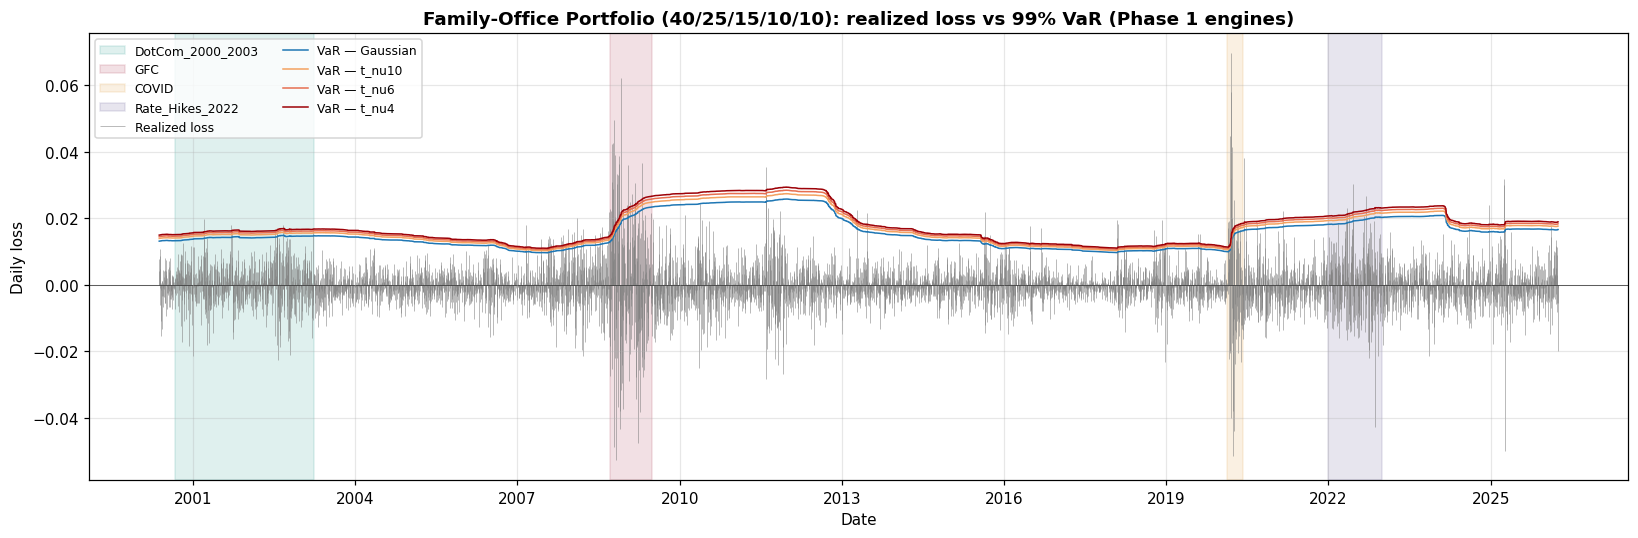

In [11]:
fig, axes = plt.subplots(len(CONFIG['portfolios']), 1,
                         figsize=(15, 5 * len(CONFIG['portfolios'])),
                         sharex=True)
axes = np.atleast_1d(axes)

for ax, port in zip(axes, CONFIG['portfolios']):
    fc_all = forecasts_by_port[port]
    common_idx = fc_all.index
    L = (-returns[port]).reindex(common_idx)

    for win_name, w in STRESS_WINDOWS.items():
        ax.axvspan(pd.Timestamp(w['start']), pd.Timestamp(w['end']),
                   color=CONFIG['window_colors'][win_name],
                   alpha=0.15, zorder=0, label=f'{win_name}')

    ax.vlines(L.index, 0, L.values, color='grey', lw=0.35, zorder=1,
              label='Realized loss')

    for eng in CONFIG['engines']:
        ax.plot(fc_all.index, fc_all[f'{eng}_VaR'], lw=1.0,
                color=CONFIG['engine_colors'][eng], zorder=2,
                label=f'VaR — {eng}')

    ax.axhline(0, color='black', lw=0.5, zorder=1)
    ax.set_title(f"{CONFIG['portfolio_labels'][port]}: realized loss vs 99% VaR (Phase 1 engines)",
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('Daily loss')
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend(loc='upper left', fontsize=8, ncol=2)

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

### Stress-zoom panels

Same data, zoomed to each named stress window. The visual fan-out between engines is most striking in these regimes — useful for reading the stress periods.

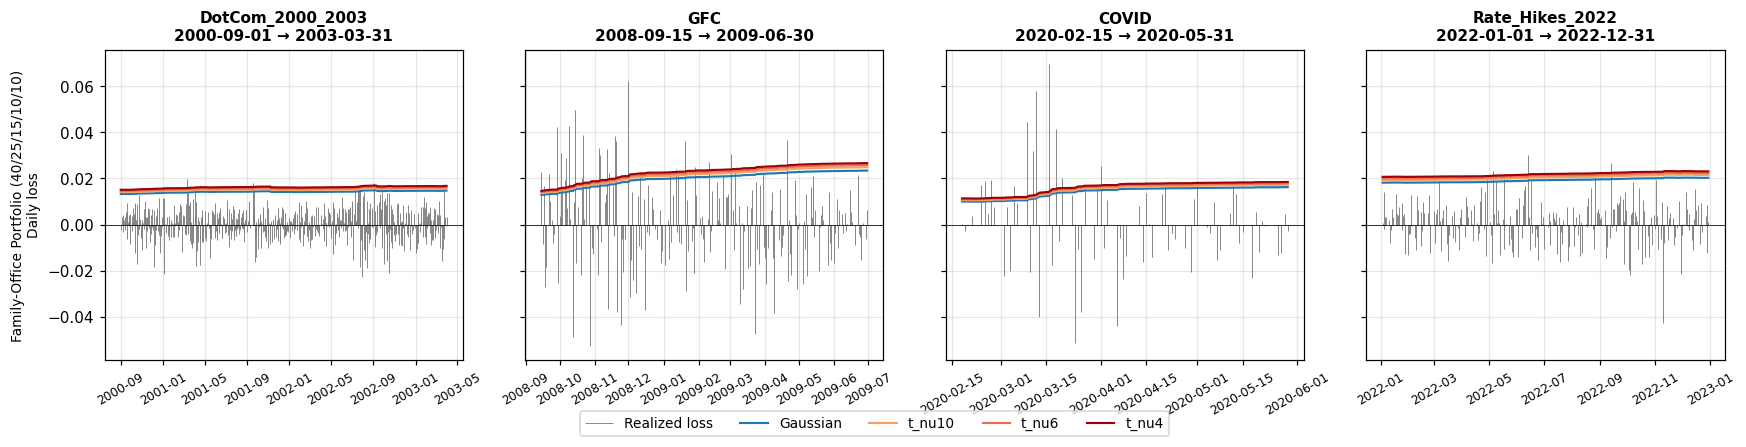

In [12]:
fig, axes = plt.subplots(len(CONFIG['portfolios']), len(STRESS_WINDOWS),
                         figsize=(16, 4 * len(CONFIG['portfolios'])),
                         sharey='row', squeeze=False)

for i, port in enumerate(CONFIG['portfolios']):
    fc_all = forecasts_by_port[port]
    common_idx = fc_all.index
    L = (-returns[port]).reindex(common_idx)

    for j, (win_name, w) in enumerate(STRESS_WINDOWS.items()):
        ax = axes[i, j]
        s, e = pd.Timestamp(w['start']), pd.Timestamp(w['end'])
        mask = (common_idx >= s) & (common_idx <= e)
        L_sub = L.loc[mask]
        fc_sub = fc_all.loc[mask]

        ax.vlines(L_sub.index, 0, L_sub.values, color='grey', lw=0.6,
                  label='Realized loss')
        for eng in CONFIG['engines']:
            ax.plot(fc_sub.index, fc_sub[f'{eng}_VaR'], lw=1.4,
                    color=CONFIG['engine_colors'][eng], label=f'{eng}')

        ax.axhline(0, color='black', lw=0.5)
        if i == 0:
            ax.set_title(f'{win_name}\n{w["start"]} → {w["end"]}', fontsize=10, fontweight='bold')
        if j == 0:
            ax.set_ylabel(f'{CONFIG["portfolio_labels"][port]}\nDaily loss', fontsize=9)
        ax.tick_params(axis='x', rotation=30, labelsize=8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, fontsize=9, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.show()

---
## 10  Save Scorecards

These four tables are the inputs to the synthesis in NB08. The two `es_*` tables are new in this revision and feed the ES adequacy discussion.

In [13]:
os.makedirs('data/scorecards', exist_ok=True)
overall.to_csv('data/scorecards/overall.csv')
stress.to_csv('data/scorecards/stress.csv')
es_overall.to_csv('data/scorecards/es_overall.csv')
es_stress.to_csv('data/scorecards/es_stress.csv')
print('Saved → data/scorecards/overall.csv     shape={}'.format(overall.shape))
print('Saved → data/scorecards/stress.csv      shape={}'.format(stress.shape))
print('Saved → data/scorecards/es_overall.csv  shape={}'.format(es_overall.shape))
print('Saved → data/scorecards/es_stress.csv   shape={}'.format(es_stress.shape))

Saved → data/scorecards/overall.csv     shape=(4, 14)
Saved → data/scorecards/stress.csv      shape=(16, 14)
Saved → data/scorecards/es_overall.csv  shape=(4, 11)
Saved → data/scorecards/es_stress.csv   shape=(16, 11)


---
## 11  Summary & Next Steps

### Phase 1 is complete

With this notebook, the project answers a self-contained question:

> *Among parametric rolling-window engines, which (Gaussian, $t_{10}$, $t_{6}$, $t_{4}$) most accurately captures 99% tail risk for the 60/40 and FO portfolio portfolios over 1994-2026?*

The four engines have now been compared on five formal axes derived in §4:

1. **VaR coverage** — Kupiec $\mathrm{LR}_{\mathrm{uc}}$ on overall and stress sub-samples.
2. **VaR clustering** — Christoffersen $\mathrm{LR}_{\mathrm{ind}}$.
3. **Joint VaR adequacy** — Christoffersen $\mathrm{LR}_{\mathrm{cc}}$.
4. **ES severity (conditional)** — McNeil-Frey bootstrap p-value on exceedance residuals.
5. **ES adequacy (full sample)** — Acerbi-Székely $Z_2$ with bootstrap CI.

The headline pattern to look for across these tests:

- Going Gaussian → $t_4$ should monotonically improve all distributional metrics (Kupiec, McNeil-Frey, $|Z_2|$) while leaving clustering (Christoffersen $\mathrm{LR}_{\mathrm{ind}}$) approximately unchanged.
- Even $t_4$ is expected to *still reject* most tests, because the underlying problem is dynamic, not distributional.
- The sign of $Z_2$ on Gaussian is the cleanest single number to communicate "ES is systematically too optimistic" to a non-technical audience.

### Phase 2 hypothesis (testable in notebook 05)

Drawing on the methodology in §4.9, the predicted pattern for the Phase 2 GARCH-FHS engine is:

- $\mathrm{LR}_{\mathrm{ind}}$ falls by an order of magnitude versus the Phase 1 engines, because the GARCH-filtered conditional volatility adapts to volatility regimes within days rather than years.
- $\mathrm{LR}_{\mathrm{uc}}$ falls modestly if the FHS engine uses bootstrap of standardised residuals (a non-parametric approach to fat tails), or substantially if it uses Student-t innovations.
- ES tests (McNeil-Frey and $Z_2$) should also improve sharply because GARCH-FHS adapts conditional severity dynamically — though they may not fully pass on the 60/40 portfolio.

### Next notebook — `05_GARCH_FHS.ipynb`

1. Fit GARCH(1,1) to each portfolio's rolling 4-year return window.
2. Extract standardised residuals; resample with replacement (filtered historical simulation).
3. Use resampled standardised innovations × forecast conditional volatility to construct empirical VaR/ES at $\alpha = 99\%$.
4. Run the **same five-test battery** on the new engine (VaR + ES). The two new ES test functions from §5 of this notebook should be lifted into `src/risk.py` so NB05 can import them.
5. Append rows to the overall + ES scorecards and produce the final consolidated ranking.